# SEG04 Transfer Learning for Crack Semantic Segmentation

**Course Instructor**  
Dr. Md Rifat Ahmmad Rashid  
Associate Professor  
East West University Bangladesh

## Module Focus

This notebook uses pretrained semantic segmentation models from `torchvision` for dense crack-mask prediction. The goal is to demonstrate how a model pretrained for general semantic segmentation can be adapted to a binary crack segmentation problem.

## Learning Goals

1. Use pretrained semantic segmentation models for dense prediction.
2. Replace classifier heads for binary crack segmentation.
3. Compare frozen-backbone and fine-tuned transfer-learning workflows.

## Key Concepts

1. Fully convolutional semantic segmentation models.
2. DeepLabV3 and FCN heads in `torchvision`.
3. Backbone freezing and fine-tuning.
4. Class imbalance and binary classifier-head replacement.
5. Confidence maps and per-pixel thresholding.

## Notebook Tasks

1. Load a pretrained `torchvision` semantic segmentation model.
2. Replace the final segmentation classifier for one foreground class.
3. Run inference on crack images before fine-tuning.
4. Fine-tune on a small crack segmentation subset.
5. Compare pretrained, frozen-backbone, and fine-tuned outputs.

## Expected Outputs

1. Pretrained model inference examples.
2. Fine-tuned crack segmentation prediction grids.
3. Frozen versus fine-tuned metric table.
4. Confidence heatmaps and threshold sensitivity analysis.

## Important Teaching Note

This notebook is configured for demonstration speed. It uses a small subset, resized images, 10 epochs, and mixed precision where CUDA is available. It is **not optimized for final research-level accuracy**. For a publication-grade experiment, increase the data volume, image size, training epochs, augmentation strength, validation protocol, and hyperparameter tuning.

## 1. Environment Setup

The following cell imports all required packages, fixes random seeds, detects the training device, and enables GPU-friendly settings.

In [1]:
# Core Python libraries
import os
import random
import time
from pathlib import Path
from collections import defaultdict

# Numerical and data handling libraries
import numpy as np
import pandas as pd

# Image processing and visualization libraries
from PIL import Image
import matplotlib.pyplot as plt

# PyTorch and torchvision
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.transforms import functional as TF
from torchvision.models.segmentation import deeplabv3_resnet50, fcn_resnet50

# Progress bars for long loops
from tqdm.auto import tqdm

# Reproducibility helper
def set_seed(seed=42):
    """Set seeds for repeatable classroom demonstrations."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"

# Speed-related settings for CUDA
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Torch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)
print("Mixed precision enabled:", AMP_ENABLED)

Torch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Device: cuda
Mixed precision enabled: True


## 2. Configuration

The dataset path follows the same setting used in the previous SEG notebooks. Several fallback paths are included because Kaggle sometimes exposes datasets under slightly different directory names.

In [2]:
# -------------------------------------------------------------------------
# Main dataset path supplied for this course notebook.
# -------------------------------------------------------------------------
PRIMARY_DATA_ROOT = Path(
    "/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset"
)

# Additional fallback paths commonly used by Kaggle.
DATA_ROOT_CANDIDATES = [
    PRIMARY_DATA_ROOT,
    Path("/kaggle/input/crack-segmentation-dataset/crack_segmentation_dataset"),
    Path("/kaggle/input/crack-segmentation-dataset"),
    Path("/kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset"),
]

# Fast teaching configuration.
# These values reduce runtime. Increase them for a stronger experiment.
IMG_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 10

# Use a small subset for fast demonstration.
# Set these to None if you want to train on the full discovered dataset.
MAX_TRAIN_SAMPLES = 120
MAX_VAL_SAMPLES = 40

# DataLoader workers. In Kaggle, 2 is usually safe.
NUM_WORKERS = 0

# Optimizer settings
LR_FROZEN = 1e-3
LR_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4

# Prediction threshold used before calibration
DEFAULT_THRESHOLD = 0.50

# Output directory for saved masks and tables
OUTPUT_DIR = Path("/kaggle/working/seg04_transfer_learning_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

Output directory: /kaggle/working/seg04_transfer_learning_outputs


## 3. Dataset Discovery and Image-Mask Pairing

This section searches for image and mask files from `images`, `masks`, `train`, and `test` style folders. The pairing function uses normalized file stems, so names such as `image_001.jpg` and `image_001_mask.png` can still be paired.

In [3]:
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def find_existing_root(candidates):
    """Return the first dataset root that exists."""
    for root in candidates:
        if root.exists():
            return root
    raise FileNotFoundError(
        "Dataset root was not found. Please check the Kaggle dataset mount path."
    )

def normalize_stem(path):
    """
    Normalize file names so that image and mask names can be paired.

    Examples:
    image_001.jpg       -> image_001
    image_001_mask.png  -> image_001
    image_001-mask.png  -> image_001
    """
    stem = path.stem.lower()
    for suffix in ["_mask", "-mask", "_label", "-label", "_gt", "-gt", "_seg", "-seg"]:
        if stem.endswith(suffix):
            stem = stem[: -len(suffix)]
    return stem

def collect_image_files(root):
    """Collect all image-like files under the dataset root with a progress bar."""
    all_files = list(root.rglob("*"))
    image_files = []
    for p in tqdm(all_files, desc="Scanning dataset files"):
        if p.is_file() and p.suffix.lower() in IMG_EXTENSIONS:
            image_files.append(p)
    return image_files

def split_image_and_mask_candidates(files):
    """
    Separate candidate image files and candidate mask files using folder names
    and file-name hints.
    """
    image_candidates = []
    mask_candidates = []

    for p in tqdm(files, desc="Classifying image/mask candidates"):
        lower_parts = [part.lower() for part in p.parts]
        lower_name = p.name.lower()

        looks_like_mask = (
            "mask" in lower_parts
            or "masks" in lower_parts
            or "label" in lower_parts
            or "labels" in lower_parts
            or "groundtruth" in lower_parts
            or "ground_truth" in lower_parts
            or lower_name.endswith(("_mask.png", "-mask.png", "_gt.png", "-gt.png"))
        )

        if looks_like_mask:
            mask_candidates.append(p)
        else:
            image_candidates.append(p)

    return image_candidates, mask_candidates

def discover_pairs(root):
    """Discover paired image-mask examples from the dataset."""
    files = collect_image_files(root)
    image_candidates, mask_candidates = split_image_and_mask_candidates(files)

    mask_by_stem = defaultdict(list)
    for m in mask_candidates:
        mask_by_stem[normalize_stem(m)].append(m)

    pairs = []
    for img in tqdm(image_candidates, desc="Pairing images with masks"):
        key = normalize_stem(img)
        if key in mask_by_stem:
            # If there are multiple masks with the same key, use the first one.
            pairs.append((img, mask_by_stem[key][0]))

    return pairs, image_candidates, mask_candidates

DATA_ROOT = find_existing_root(DATA_ROOT_CANDIDATES)
print("Using dataset root:", DATA_ROOT)

pairs, image_candidates, mask_candidates = discover_pairs(DATA_ROOT)

print(f"Image candidates: {len(image_candidates)}")
print(f"Mask candidates : {len(mask_candidates)}")
print(f"Paired samples  : {len(pairs)}")

if len(pairs) == 0:
    raise RuntimeError(
        "No image-mask pairs were found. Please inspect the folder structure and update the pairing rule."
    )

# Show a few discovered pairs for verification.
for img_path, mask_path in pairs[:5]:
    print("IMAGE:", img_path)
    print("MASK :", mask_path)
    print("-" * 80)

Using dataset root: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset


Scanning dataset files:   0%|          | 0/45201 [00:00<?, ?it/s]

Classifying image/mask candidates:   0%|          | 0/45192 [00:00<?, ?it/s]

Pairing images with masks:   0%|          | 0/22596 [00:00<?, ?it/s]

Image candidates: 22596
Mask candidates : 22596
Paired samples  : 22596
IMAGE: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images/DeepCrack_IMG_6469-7.jpg
MASK : /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/DeepCrack_IMG_6469-7.jpg
--------------------------------------------------------------------------------
IMAGE: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images/Rissbilder_for_Florian_9S6A2828_80_1698_3421_3098.jpg
MASK : /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/masks/Rissbilder_for_Florian_9S6A2828_80_1698_3421_3098.jpg
--------------------------------------------------------------------------------
IMAGE: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset/images/Rissbilder_for_Florian_9S6A2880_131_2019_3358_3435.jpg
MASK : /kaggle/input/datasets/

## 4. Train-Validation Split

The split is randomized for demonstration. For final experiments, keep a fixed split file so that different models are compared under identical validation data.

In [4]:
# Shuffle pairs reproducibly.
pairs = pairs.copy()
random.shuffle(pairs)

# 80/20 split for classroom demonstration.
split_idx = int(0.80 * len(pairs))
train_pairs_full = pairs[:split_idx]
val_pairs_full = pairs[split_idx:]

# Fast-run subset selection.
train_pairs = train_pairs_full[:MAX_TRAIN_SAMPLES] if MAX_TRAIN_SAMPLES else train_pairs_full
val_pairs = val_pairs_full[:MAX_VAL_SAMPLES] if MAX_VAL_SAMPLES else val_pairs_full

print(f"Full train pairs: {len(train_pairs_full)}")
print(f"Full val pairs  : {len(val_pairs_full)}")
print(f"Used train pairs: {len(train_pairs)}")
print(f"Used val pairs  : {len(val_pairs)}")

Full train pairs: 18076
Full val pairs  : 4520
Used train pairs: 120
Used val pairs  : 40


## 5. Visual Verification of Image-Mask Pairs

This quick grid helps verify that the dataset pairing logic is correct before model training starts.

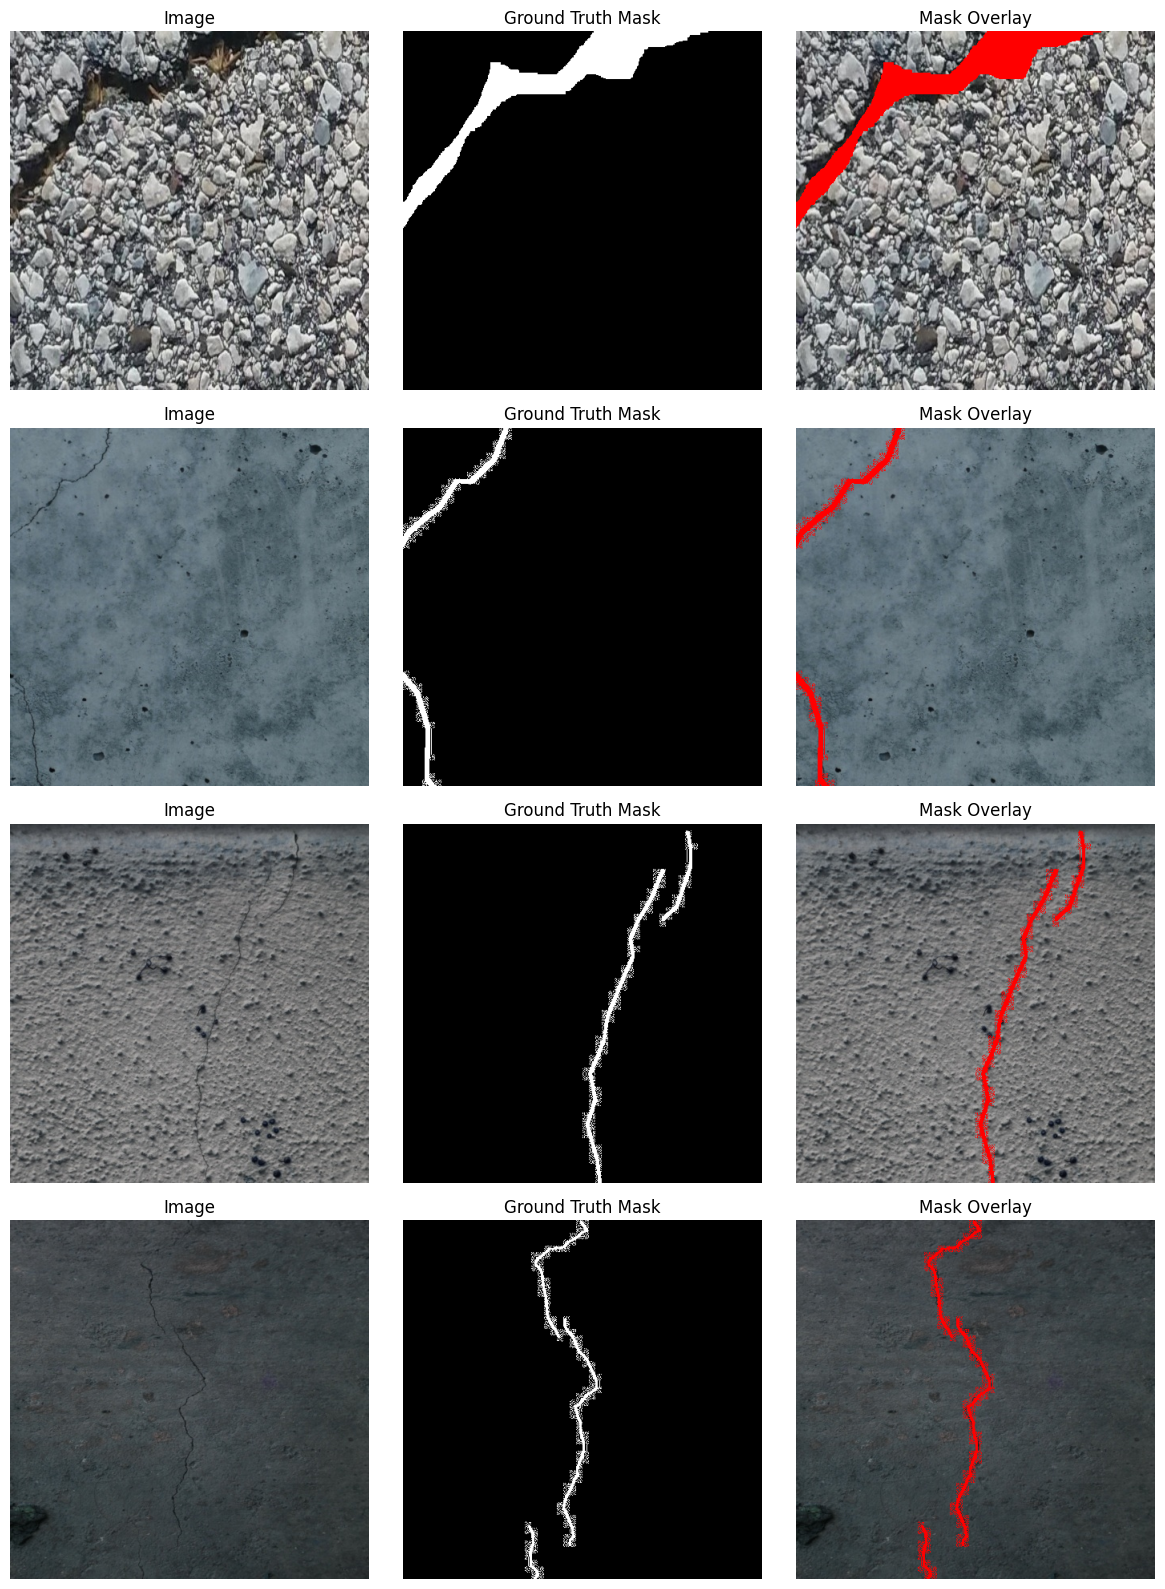

In [5]:
def load_rgb(path):
    """Load an image as RGB."""
    return Image.open(path).convert("RGB")

def load_mask(path):
    """Load a binary mask as a single-channel image."""
    return Image.open(path).convert("L")

def show_pair_grid(pairs, n=4):
    """Display image, mask, and overlay for a few samples."""
    n = min(n, len(pairs))
    selected = random.sample(pairs, n)

    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, (img_path, mask_path) in enumerate(selected):
        img = np.array(load_rgb(img_path))
        mask = np.array(load_mask(mask_path)) > 127

        overlay = img.copy()
        overlay[mask] = (255, 0, 0)

        axes[row, 0].imshow(img)
        axes[row, 0].set_title("Image")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(mask, cmap="gray")
        axes[row, 1].set_title("Ground Truth Mask")
        axes[row, 1].axis("off")

        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title("Mask Overlay")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.show()

show_pair_grid(train_pairs, n=4)

## 6. PyTorch Dataset for Binary Crack Segmentation

The dataset class returns normalized images and binary masks. Light augmentations are used only for training.

In [6]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class CrackSegmentationDataset(Dataset):
    """
    PyTorch Dataset for paired crack images and binary masks.

    Each item returns:
    - image tensor: [3, H, W], normalized with ImageNet statistics
    - mask tensor : [1, H, W], values 0 or 1
    - name        : file name for debugging and visualization
    """

    def __init__(self, pairs, img_size=256, train=False):
        self.pairs = list(pairs)
        self.img_size = img_size
        self.train = train

    def __len__(self):
        return len(self.pairs)

    def _augment(self, image, mask):
        """Apply simple geometric augmentations to both image and mask."""
        if random.random() < 0.50:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        if random.random() < 0.20:
            image = TF.vflip(image)
            mask = TF.vflip(mask)

        # Small random rotation helps the model see cracks with different orientations.
        if random.random() < 0.30:
            angle = random.uniform(-10, 10)
            image = TF.rotate(image, angle, interpolation=transforms.InterpolationMode.BILINEAR)
            mask = TF.rotate(mask, angle, interpolation=transforms.InterpolationMode.NEAREST)

        return image, mask

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        image = load_rgb(img_path)
        mask = load_mask(mask_path)

        # Resize images and masks to a fixed size for fast batching.
        image = TF.resize(image, [self.img_size, self.img_size], interpolation=transforms.InterpolationMode.BILINEAR)
        mask = TF.resize(mask, [self.img_size, self.img_size], interpolation=transforms.InterpolationMode.NEAREST)

        if self.train:
            image, mask = self._augment(image, mask)

        # Convert image to tensor and normalize using ImageNet statistics.
        image = TF.to_tensor(image)
        image = (image - IMAGENET_MEAN) / IMAGENET_STD

        # Convert mask to a binary tensor.
        mask = TF.to_tensor(mask)
        mask = (mask > 0.5).float()

        return image, mask, img_path.name

train_ds = CrackSegmentationDataset(train_pairs, img_size=IMG_SIZE, train=True)
val_ds = CrackSegmentationDataset(val_pairs, img_size=IMG_SIZE, train=False)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
)

images, masks, names = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Mask batch shape :", masks.shape)
print("Example names    :", names[:2])

Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape : torch.Size([4, 1, 256, 256])
Example names    : ('CRACK500_20160316_142014_1_1081.jpg', 'Rissbilder_for_Florian_9S6A2844_136_665_2999_2796.jpg')


## 7. Pretrained Model Inference Before Fine-Tuning

The pretrained DeepLabV3 model was trained on natural image semantic classes, not crack masks. Therefore, its raw prediction is not expected to identify cracks correctly. The purpose of this section is to show the starting behavior before task-specific adaptation.

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 199MB/s]


Loaded pretrained DeepLabV3-ResNet50 weights.


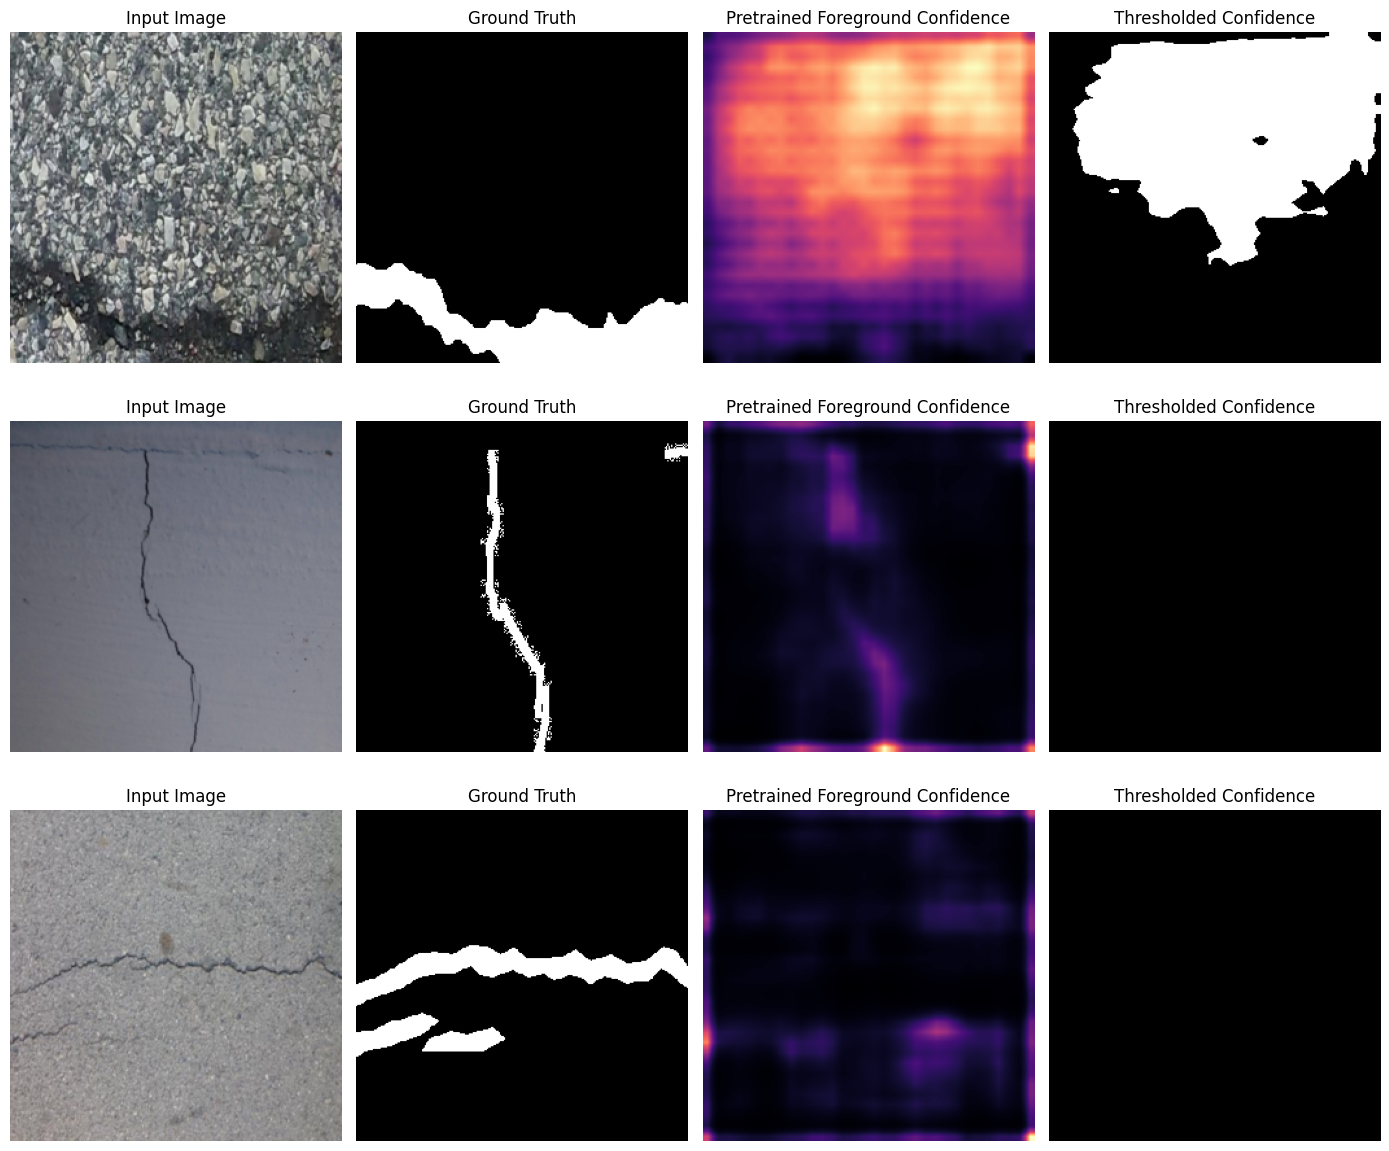

In [7]:
def denormalize_image(tensor):
    """Convert normalized tensor [3,H,W] back to a displayable RGB image."""
    img = tensor * IMAGENET_STD + IMAGENET_MEAN
    img = img.clamp(0, 1)
    img = img.permute(1, 2, 0).numpy()
    return img

def build_pretrained_deeplab_multiclass():
    """
    Load a pretrained DeepLabV3-ResNet50 model for demonstration.

    If pretrained weights cannot be downloaded in the current Kaggle session,
    the function falls back to an untrained model and prints a warning.
    """
    try:
        from torchvision.models.segmentation import DeepLabV3_ResNet50_Weights
        weights = DeepLabV3_ResNet50_Weights.DEFAULT
        model = deeplabv3_resnet50(weights=weights)
        print("Loaded pretrained DeepLabV3-ResNet50 weights.")
        return model, weights
    except Exception as e:
        print("Could not load pretrained weights. Falling back to random initialization.")
        print("Reason:", repr(e))
        model = deeplabv3_resnet50(weights=None, weights_backbone=None)
        return model, None

@torch.no_grad()
def pretrained_inference_grid(model, loader, max_samples=3):
    """
    Visualize the pretrained model's non-background confidence.

    For VOC-style pretrained DeepLabV3, class index 0 is background.
    We plot 1 - P(background) as a generic foreground confidence map.
    """
    model.eval()
    model.to(DEVICE)

    images, masks, names = next(iter(loader))
    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    logits = model(images)["out"]
    probs = torch.softmax(logits, dim=1)

    # Generic foreground confidence, not crack-specific probability.
    fg_conf = 1.0 - probs[:, 0:1]

    n = min(max_samples, images.size(0))
    fig, axes = plt.subplots(n, 4, figsize=(14, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img_vis = denormalize_image(images[i].detach().cpu())
        mask_vis = masks[i, 0].detach().cpu().numpy()
        conf_vis = fg_conf[i, 0].detach().cpu().numpy()

        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask_vis, cmap="gray")
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(conf_vis, cmap="magma")
        axes[i, 2].set_title("Pretrained Foreground Confidence")
        axes[i, 2].axis("off")

        axes[i, 3].imshow(conf_vis > 0.50, cmap="gray")
        axes[i, 3].set_title("Thresholded Confidence")
        axes[i, 3].axis("off")

    plt.tight_layout()
    plt.show()

pretrained_demo_model, pretrained_weights = build_pretrained_deeplab_multiclass()
pretrained_inference_grid(pretrained_demo_model, val_loader, max_samples=3)

# Free GPU memory after the demonstration.
del pretrained_demo_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 8. Replace the Segmentation Classifier Head for Binary Crack Masks

DeepLabV3 originally predicts multiple semantic classes. For crack segmentation, we replace the final classifier with a one-channel output layer. The output logit is then converted to a foreground probability using the sigmoid function.

In [8]:
def replace_deeplab_head(model, out_channels=1):
    """
    Replace the DeepLabV3 classifier and auxiliary classifier with binary heads.

    The classifier output is a single logit channel:
    logit > 0 means more likely crack foreground.
    """
    # Replace main segmentation head.
    in_channels = model.classifier[-1].in_channels
    model.classifier[-1] = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    # Replace auxiliary head if the model has one.
    if hasattr(model, "aux_classifier") and model.aux_classifier is not None:
        aux_in_channels = model.aux_classifier[-1].in_channels
        model.aux_classifier[-1] = nn.Conv2d(aux_in_channels, out_channels, kernel_size=1)

    return model

def replace_fcn_head(model, out_channels=1):
    """
    Optional FCN head replacement.

    This function is included to show that the same transfer-learning idea
    applies to FCN models as well.
    """
    in_channels = model.classifier[-1].in_channels
    model.classifier[-1] = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    if hasattr(model, "aux_classifier") and model.aux_classifier is not None:
        aux_in_channels = model.aux_classifier[-1].in_channels
        model.aux_classifier[-1] = nn.Conv2d(aux_in_channels, out_channels, kernel_size=1)

    return model

def build_binary_deeplab(pretrained=True, freeze_backbone=False):
    """
    Build a DeepLabV3 model for binary crack segmentation.

    Parameters:
    - pretrained=True: start from pretrained segmentation weights if available
    - freeze_backbone=True: train only the classifier heads
    """
    if pretrained:
        try:
            from torchvision.models.segmentation import DeepLabV3_ResNet50_Weights
            weights = DeepLabV3_ResNet50_Weights.DEFAULT
            model = deeplabv3_resnet50(weights=weights)
            print("Loaded pretrained DeepLabV3 weights.")
        except Exception as e:
            print("Pretrained weights unavailable. Using random initialization.")
            print("Reason:", repr(e))
            model = deeplabv3_resnet50(weights=None, weights_backbone=None)
    else:
        model = deeplabv3_resnet50(weights=None, weights_backbone=None)

    model = replace_deeplab_head(model, out_channels=1)

    if freeze_backbone:
        # Freeze low-level and high-level feature extractor layers.
        for param in model.backbone.parameters():
            param.requires_grad = False

    return model

def count_trainable_parameters(model):
    """Count parameters that will be updated by the optimizer."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Build one model only for architecture verification.
model_check = build_binary_deeplab(pretrained=True, freeze_backbone=True)
print(model_check)
print("Trainable parameters:", count_trainable_parameters(model_check))

del model_check
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Loaded pretrained DeepLabV3 weights.
DeepLabV3(
  (backbone): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(i

## 9. Loss Functions and Segmentation Metrics

Binary crack segmentation is imbalanced because crack pixels usually occupy a small part of the image. The training loss combines weighted BCE and Dice loss.

In [9]:
def estimate_pos_weight(loader, max_batches=20):
    """
    Estimate foreground/background imbalance from masks.

    pos_weight > 1 gives more penalty to missed crack pixels in BCE.
    The value is clipped to prevent unstable gradients in a small teaching run.
    """
    pos_pixels = 0.0
    neg_pixels = 0.0

    for batch_idx, (_, masks, _) in enumerate(tqdm(loader, desc="Estimating class imbalance")):
        pos_pixels += masks.sum().item()
        neg_pixels += masks.numel() - masks.sum().item()

        if batch_idx + 1 >= max_batches:
            break

    raw_weight = neg_pixels / max(pos_pixels, 1.0)
    clipped_weight = float(np.clip(raw_weight, 1.0, 50.0))
    return clipped_weight

POS_WEIGHT_VALUE = estimate_pos_weight(train_loader)
print("Estimated BCE pos_weight:", POS_WEIGHT_VALUE)

def dice_loss_from_logits(logits, targets, smooth=1e-6):
    """Dice loss computed from logits."""
    probs = torch.sigmoid(logits)
    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (probs * targets).sum(dim=1)
    denominator = probs.sum(dim=1) + targets.sum(dim=1)

    dice = (2.0 * intersection + smooth) / (denominator + smooth)
    return 1.0 - dice.mean()

def focal_loss_from_logits(logits, targets, alpha=0.75, gamma=2.0):
    """
    Optional focal loss for highly imbalanced segmentation.

    This notebook trains with BCE + Dice by default, but focal loss is included
    because it is a useful alternative when thin cracks are missed.
    """
    bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    probs = torch.sigmoid(logits)
    pt = torch.where(targets == 1, probs, 1 - probs)
    focal_weight = alpha * (1 - pt).pow(gamma)
    return (focal_weight * bce).mean()

class BCEDiceLoss(nn.Module):
    """Combined weighted BCE and Dice loss."""
    def __init__(self, pos_weight_value=1.0, bce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.register_buffer("pos_weight", torch.tensor([pos_weight_value], dtype=torch.float32))
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            pos_weight=self.pos_weight.to(logits.device),
        )
        dice = dice_loss_from_logits(logits, targets)
        return self.bce_weight * bce + self.dice_weight * dice

def compute_binary_stats(preds, targets):
    """Compute confusion statistics for binary masks."""
    preds = preds.bool()
    targets = targets.bool()

    tp = (preds & targets).sum().item()
    fp = (preds & ~targets).sum().item()
    fn = (~preds & targets).sum().item()
    tn = (~preds & ~targets).sum().item()

    return tp, fp, fn, tn

def metrics_from_stats(tp, fp, fn, tn, eps=1e-7):
    """Convert confusion statistics to segmentation metrics."""
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    accuracy = (tp + tn) / (tp + fp + fn + tn + eps)

    return {
        "IoU": iou,
        "Dice": dice,
        "Precision": precision,
        "Recall": recall,
        "Accuracy": accuracy,
    }

Estimating class imbalance:   0%|          | 0/30 [00:00<?, ?it/s]

Estimated BCE pos_weight: 33.45024870718261


## 10. Training and Evaluation Utilities with Mixed Precision

The training loop uses automatic mixed precision on CUDA. This often reduces GPU memory usage and speeds up training.

In [10]:
def get_optimizer(model, lr):
    """Create AdamW optimizer for trainable parameters only."""
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.AdamW(trainable_params, lr=lr, weight_decay=WEIGHT_DECAY)

def forward_logits(model, images):
    """Forward pass helper for torchvision segmentation models."""
    outputs = model(images)
    return outputs["out"]

def train_one_epoch(model, loader, optimizer, criterion, scaler, epoch, model_name):
    """Train the model for one epoch with progress bars."""
    model.train()

    running_loss = 0.0
    tp_total = fp_total = fn_total = tn_total = 0

    pbar = tqdm(loader, desc=f"{model_name} | Epoch {epoch:02d} train", leave=False)

    for images, masks, _ in pbar:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision is active only when CUDA is available.
        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = forward_logits(model, images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        with torch.no_grad():
            probs = torch.sigmoid(logits)
            preds = probs > DEFAULT_THRESHOLD
            tp, fp, fn, tn = compute_binary_stats(preds, masks > 0.5)
            tp_total += tp
            fp_total += fp
            fn_total += fn
            tn_total += tn

        batch_metrics = metrics_from_stats(tp_total, fp_total, fn_total, tn_total)
        pbar.set_postfix(loss=f"{loss.item():.4f}", dice=f"{batch_metrics['Dice']:.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_metrics = metrics_from_stats(tp_total, fp_total, fn_total, tn_total)
    epoch_metrics["Loss"] = epoch_loss
    return epoch_metrics

@torch.no_grad()
def evaluate_model(model, loader, criterion=None, threshold=0.5, model_name="model"):
    """Evaluate a segmentation model on the validation set."""
    model.eval()

    running_loss = 0.0
    tp_total = fp_total = fn_total = tn_total = 0
    total_samples = 0

    pbar = tqdm(loader, desc=f"{model_name} validation", leave=False)

    for images, masks, _ in pbar:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        logits = forward_logits(model, images)

        if criterion is not None:
            loss = criterion(logits, masks)
            running_loss += loss.item() * images.size(0)

        probs = torch.sigmoid(logits)
        preds = probs > threshold

        tp, fp, fn, tn = compute_binary_stats(preds, masks > 0.5)
        tp_total += tp
        fp_total += fp
        fn_total += fn
        tn_total += tn

        total_samples += images.size(0)
        batch_metrics = metrics_from_stats(tp_total, fp_total, fn_total, tn_total)
        pbar.set_postfix(dice=f"{batch_metrics['Dice']:.4f}", iou=f"{batch_metrics['IoU']:.4f}")

    metrics = metrics_from_stats(tp_total, fp_total, fn_total, tn_total)
    if criterion is not None:
        metrics["Loss"] = running_loss / max(total_samples, 1)
    return metrics

def fit_model(model, model_name, lr):
    """Complete 10-epoch training routine."""
    model = model.to(DEVICE)

    criterion = BCEDiceLoss(pos_weight_value=POS_WEIGHT_VALUE, bce_weight=0.5, dice_weight=0.5)
    optimizer = get_optimizer(model, lr=lr)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)

    history = []

    for epoch in range(1, EPOCHS + 1):
        start_time = time.time()

        train_metrics = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            scaler=scaler,
            epoch=epoch,
            model_name=model_name,
        )

        val_metrics = evaluate_model(
            model=model,
            loader=val_loader,
            criterion=criterion,
            threshold=DEFAULT_THRESHOLD,
            model_name=model_name,
        )

        elapsed = time.time() - start_time

        row = {
            "Model": model_name,
            "Epoch": epoch,
            "Train Loss": train_metrics["Loss"],
            "Train Dice": train_metrics["Dice"],
            "Train IoU": train_metrics["IoU"],
            "Val Loss": val_metrics["Loss"],
            "Val Dice": val_metrics["Dice"],
            "Val IoU": val_metrics["IoU"],
            "Val Precision": val_metrics["Precision"],
            "Val Recall": val_metrics["Recall"],
            "Runtime Sec": elapsed,
        }
        history.append(row)

        print(
            f"{model_name} | Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Loss {row['Train Loss']:.4f} | Train Dice {row['Train Dice']:.4f} | "
            f"Val Loss {row['Val Loss']:.4f} | Val Dice {row['Val Dice']:.4f} | "
            f"Val IoU {row['Val IoU']:.4f} | Time {elapsed:.1f}s"
        )

    history_df = pd.DataFrame(history)
    return model, history_df

## 11. Train Frozen-Backbone Transfer Learning Model

In this workflow, the pretrained backbone is frozen and only the classifier heads are trained. This is faster and often useful when the dataset is small.

In [11]:
frozen_model = build_binary_deeplab(pretrained=True, freeze_backbone=True)
print("Frozen model trainable parameters:", count_trainable_parameters(frozen_model))

frozen_model, frozen_history = fit_model(
    model=frozen_model,
    model_name="DeepLabV3 Frozen Backbone",
    lr=LR_FROZEN,
)

frozen_history.to_csv(OUTPUT_DIR / "frozen_backbone_history.csv", index=False)
frozen_history.tail()

Loaded pretrained DeepLabV3 weights.
Frozen model trainable parameters: 18485762


/tmp/ipykernel_23/817764877.py:99: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)


DeepLabV3 Frozen Backbone | Epoch 01 train:   0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_23/817764877.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP_ENABLED):


DeepLabV3 Frozen Backbone validation:   0%|          | 0/10 [00:00<?, ?it/s]

DeepLabV3 Frozen Backbone | Epoch 01/10 | Train Loss 0.9642 | Train Dice 0.1341 | Val Loss 0.9281 | Val Dice 0.2160 | Val IoU 0.1211 | Time 6.5s


... (24 outputs left out)

DeepLabV3 Frozen Backbone | Epoch 10 train:   0%|          | 0/30 [00:00<?, ?it/s]

DeepLabV3 Frozen Backbone validation:   0%|          | 0/10 [00:00<?, ?it/s]

DeepLabV3 Frozen Backbone | Epoch 10/10 | Train Loss 0.6929 | Train Dice 0.2944 | Val Loss 0.8070 | Val Dice 0.3984 | Val IoU 0.2488 | Time 3.2s


,Model,Epoch,Train Loss,Train Dice,Train IoU,Val Loss,Val Dice,Val IoU,Val Precision,Val Recall,Runtime Sec
5,DeepLabV3 Frozen Backbone,6,0.741548,0.257338,0.147669,0.901224,0.348159,0.210770,0.223022,0.793242,3.244415
6,DeepLabV3 Frozen Backbone,7,0.745981,0.251530,0.143857,1.171394,0.336747,0.202463,0.224212,0.676084,3.233799
7,DeepLabV3 Frozen Backbone,8,0.742793,0.276012,0.160101,0.745164,0.364060,0.222539,0.229721,0.876818,3.243329
8,DeepLabV3 Frozen Backbone,9,0.698019,0.286210,0.167004,0.930636,0.419950,0.265783,0.295584,0.724987,3.325444
9,DeepLabV3 Frozen Backbone,10,0.692867,0.294368,0.172586,0.806952,0.398422,0.248768,0.263377,0.817684,3.243335


## 12. Train Fine-Tuned Transfer Learning Model

In this workflow, the full network is trainable. It is slower but can adapt the feature extractor more strongly to crack textures.

In [12]:
finetuned_model = build_binary_deeplab(pretrained=True, freeze_backbone=False)
print("Fine-tuned model trainable parameters:", count_trainable_parameters(finetuned_model))

finetuned_model, finetuned_history = fit_model(
    model=finetuned_model,
    model_name="DeepLabV3 Fine-Tuned",
    lr=LR_FINETUNE,
)

finetuned_history.to_csv(OUTPUT_DIR / "finetuned_history.csv", index=False)
finetuned_history.tail()

Loaded pretrained DeepLabV3 weights.
Fine-tuned model trainable parameters: 41993794


/tmp/ipykernel_23/817764877.py:99: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)


DeepLabV3 Fine-Tuned | Epoch 01 train:   0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_23/817764877.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP_ENABLED):


DeepLabV3 Fine-Tuned validation:   0%|          | 0/10 [00:00<?, ?it/s]

DeepLabV3 Fine-Tuned | Epoch 01/10 | Train Loss 0.9519 | Train Dice 0.1684 | Val Loss 0.8105 | Val Dice 0.4484 | Val IoU 0.2890 | Time 7.9s


... (24 outputs left out)

DeepLabV3 Fine-Tuned | Epoch 10 train:   0%|          | 0/30 [00:00<?, ?it/s]

DeepLabV3 Fine-Tuned validation:   0%|          | 0/10 [00:00<?, ?it/s]

DeepLabV3 Fine-Tuned | Epoch 10/10 | Train Loss 0.5340 | Train Dice 0.4664 | Val Loss 0.6546 | Val Dice 0.5460 | Val IoU 0.3755 | Time 4.9s


,Model,Epoch,Train Loss,Train Dice,Train IoU,Val Loss,Val Dice,Val IoU,Val Precision,Val Recall,Runtime Sec
5,DeepLabV3 Fine-Tuned,6,0.610926,0.406423,0.255038,0.669406,0.444987,0.286163,0.292714,0.927458,4.865407
6,DeepLabV3 Fine-Tuned,7,0.583293,0.422577,0.267890,0.632740,0.509656,0.341972,0.352743,0.918029,4.896610
7,DeepLabV3 Fine-Tuned,8,0.570295,0.434918,0.277888,0.700626,0.444645,0.285880,0.297116,0.883178,4.864846
8,DeepLabV3 Fine-Tuned,9,0.546103,0.451111,0.291248,0.672915,0.497304,0.330941,0.346214,0.882384,4.915877
9,DeepLabV3 Fine-Tuned,10,0.533966,0.466433,0.304149,0.654566,0.545978,0.375495,0.398589,0.866321,4.936221


## 13. Training and Validation Curves

These plots compare frozen-backbone and fine-tuned transfer learning. Since this notebook is configured for fast demonstration, the curves should be interpreted as a classroom baseline rather than final performance evidence.

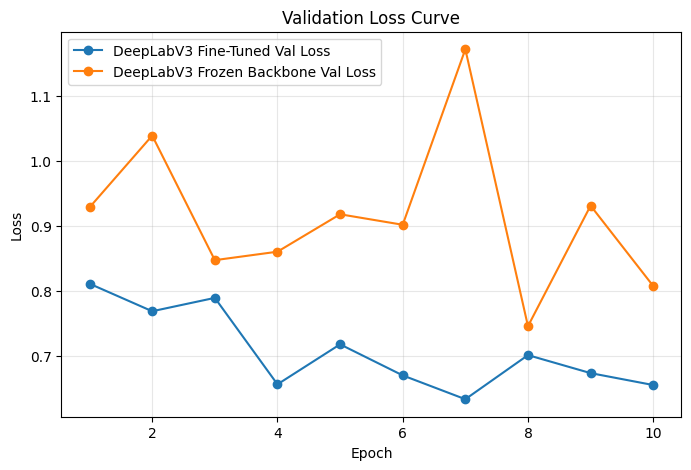

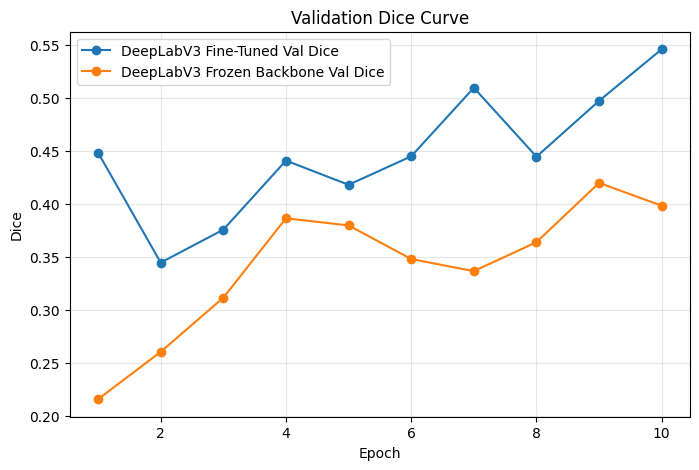

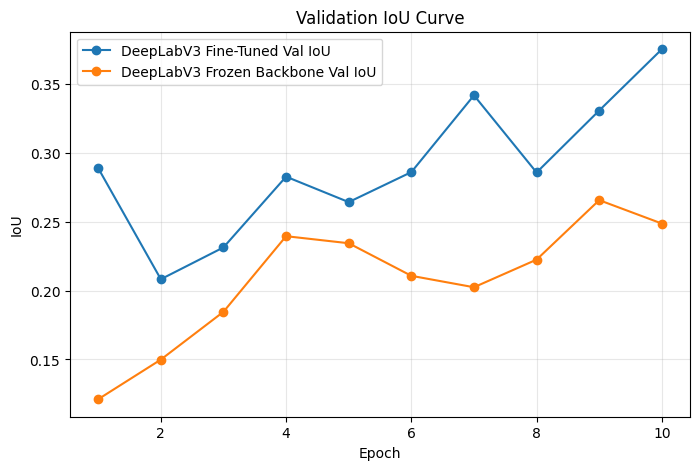

In [13]:
def plot_training_curves(histories):
    """Plot loss, Dice, and IoU curves for multiple training runs."""
    combined = pd.concat(histories, ignore_index=True)

    plt.figure(figsize=(8, 5))
    for model_name, group in combined.groupby("Model"):
        plt.plot(group["Epoch"], group["Val Loss"], marker="o", label=f"{model_name} Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Validation Loss Curve")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    for model_name, group in combined.groupby("Model"):
        plt.plot(group["Epoch"], group["Val Dice"], marker="o", label=f"{model_name} Val Dice")
    plt.xlabel("Epoch")
    plt.ylabel("Dice")
    plt.title("Validation Dice Curve")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    for model_name, group in combined.groupby("Model"):
        plt.plot(group["Epoch"], group["Val IoU"], marker="o", label=f"{model_name} Val IoU")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.title("Validation IoU Curve")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

plot_training_curves([frozen_history, finetuned_history])

## 14. Frozen versus Fine-Tuned Metric Table

The table below summarizes validation performance at the default threshold of 0.50.

In [14]:
criterion_eval = BCEDiceLoss(pos_weight_value=POS_WEIGHT_VALUE, bce_weight=0.5, dice_weight=0.5)

final_frozen_metrics = evaluate_model(
    frozen_model,
    val_loader,
    criterion=criterion_eval,
    threshold=DEFAULT_THRESHOLD,
    model_name="Frozen final"
)

final_finetuned_metrics = evaluate_model(
    finetuned_model,
    val_loader,
    criterion=criterion_eval,
    threshold=DEFAULT_THRESHOLD,
    model_name="Fine-tuned final"
)

comparison_df = pd.DataFrame([
    {"Workflow": "Frozen Backbone", **final_frozen_metrics},
    {"Workflow": "Fine-Tuned Backbone", **final_finetuned_metrics},
])

comparison_df.to_csv(OUTPUT_DIR / "frozen_vs_finetuned_metrics.csv", index=False)
comparison_df

Frozen final validation:   0%|          | 0/10 [00:00<?, ?it/s]

Fine-tuned final validation:   0%|          | 0/10 [00:00<?, ?it/s]

,Workflow,IoU,Dice,Precision,Recall,Accuracy,Loss
0,Frozen Backbone,0.248768,0.398422,0.263377,0.817684,0.893213,0.806952
1,Fine-Tuned Backbone,0.375495,0.545978,0.398589,0.866321,0.937689,0.654566


## 15. Threshold Sensitivity Analysis

Crack segmentation can be sensitive to the probability threshold because cracks are thin and foreground pixels are rare. This section evaluates several thresholds and identifies the best validation threshold by Dice score.

In [15]:
@torch.no_grad()
def threshold_sweep(model, loader, thresholds):
    """Evaluate a model at multiple foreground probability thresholds."""
    rows = []

    for threshold in tqdm(thresholds, desc="Threshold sweep"):
        metrics = evaluate_model(
            model=model,
            loader=loader,
            criterion=None,
            threshold=float(threshold),
            model_name=f"threshold={threshold:.2f}",
        )
        rows.append({"Threshold": float(threshold), **metrics})

    return pd.DataFrame(rows)

thresholds = np.linspace(0.10, 0.90, 9)
threshold_df = threshold_sweep(finetuned_model, val_loader, thresholds)
threshold_df.to_csv(OUTPUT_DIR / "threshold_sensitivity.csv", index=False)

best_threshold = float(threshold_df.sort_values("Dice", ascending=False).iloc[0]["Threshold"])
print("Best threshold by validation Dice:", best_threshold)

threshold_df

Threshold sweep:   0%|          | 0/9 [00:00<?, ?it/s]

threshold=0.10 validation:   0%|          | 0/10 [00:00<?, ?it/s]

threshold=0.20 validation:   0%|          | 0/10 [00:00<?, ?it/s]

threshold=0.30 validation:   0%|          | 0/10 [00:00<?, ?it/s]

threshold=0.40 validation:   0%|          | 0/10 [00:00<?, ?it/s]

threshold=0.50 validation:   0%|          | 0/10 [00:00<?, ?it/s]

... (2 outputs left out)

threshold=0.80 validation:   0%|          | 0/10 [00:00<?, ?it/s]

threshold=0.90 validation:   0%|          | 0/10 [00:00<?, ?it/s]

Best threshold by validation Dice: 0.9


,Threshold,IoU,Dice,Precision,Recall,Accuracy
0,0.1,0.197069,0.329252,0.198104,0.974164,0.828349
1,0.2,0.296132,0.456948,0.301239,0.945858,0.902773
2,0.3,0.329487,0.495660,0.339510,0.917764,0.919229
3,0.4,0.355048,0.524038,0.370653,0.893992,0.929769
4,0.5,0.375495,0.545978,0.398589,0.866321,0.937689
5,0.6,0.395666,0.566993,0.428757,0.836781,0.944727
6,0.7,0.413718,0.585290,0.462440,0.797026,0.951154
7,0.8,0.431619,0.602980,0.508056,0.741525,0.957770
8,0.9,0.440426,0.611522,0.586197,0.639134,0.964882


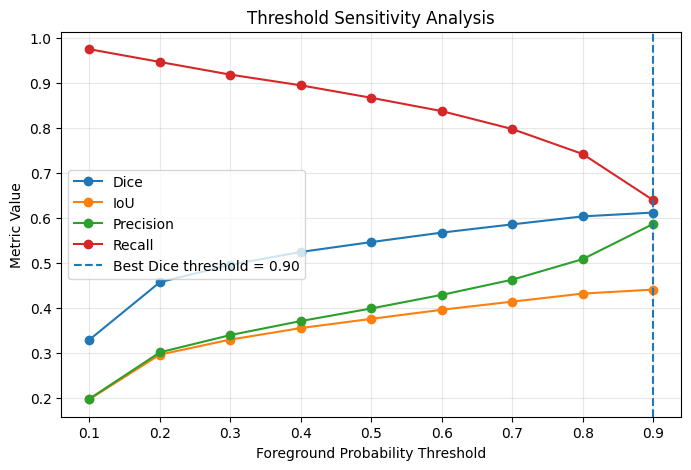

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Dice"], marker="o", label="Dice")
plt.plot(threshold_df["Threshold"], threshold_df["IoU"], marker="o", label="IoU")
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.axvline(best_threshold, linestyle="--", label=f"Best Dice threshold = {best_threshold:.2f}")
plt.xlabel("Foreground Probability Threshold")
plt.ylabel("Metric Value")
plt.title("Threshold Sensitivity Analysis")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 16. Prediction Grids and Confidence Heatmaps

The following grids show image, ground truth, probability heatmap, and thresholded prediction. This is the most important qualitative diagnostic section.

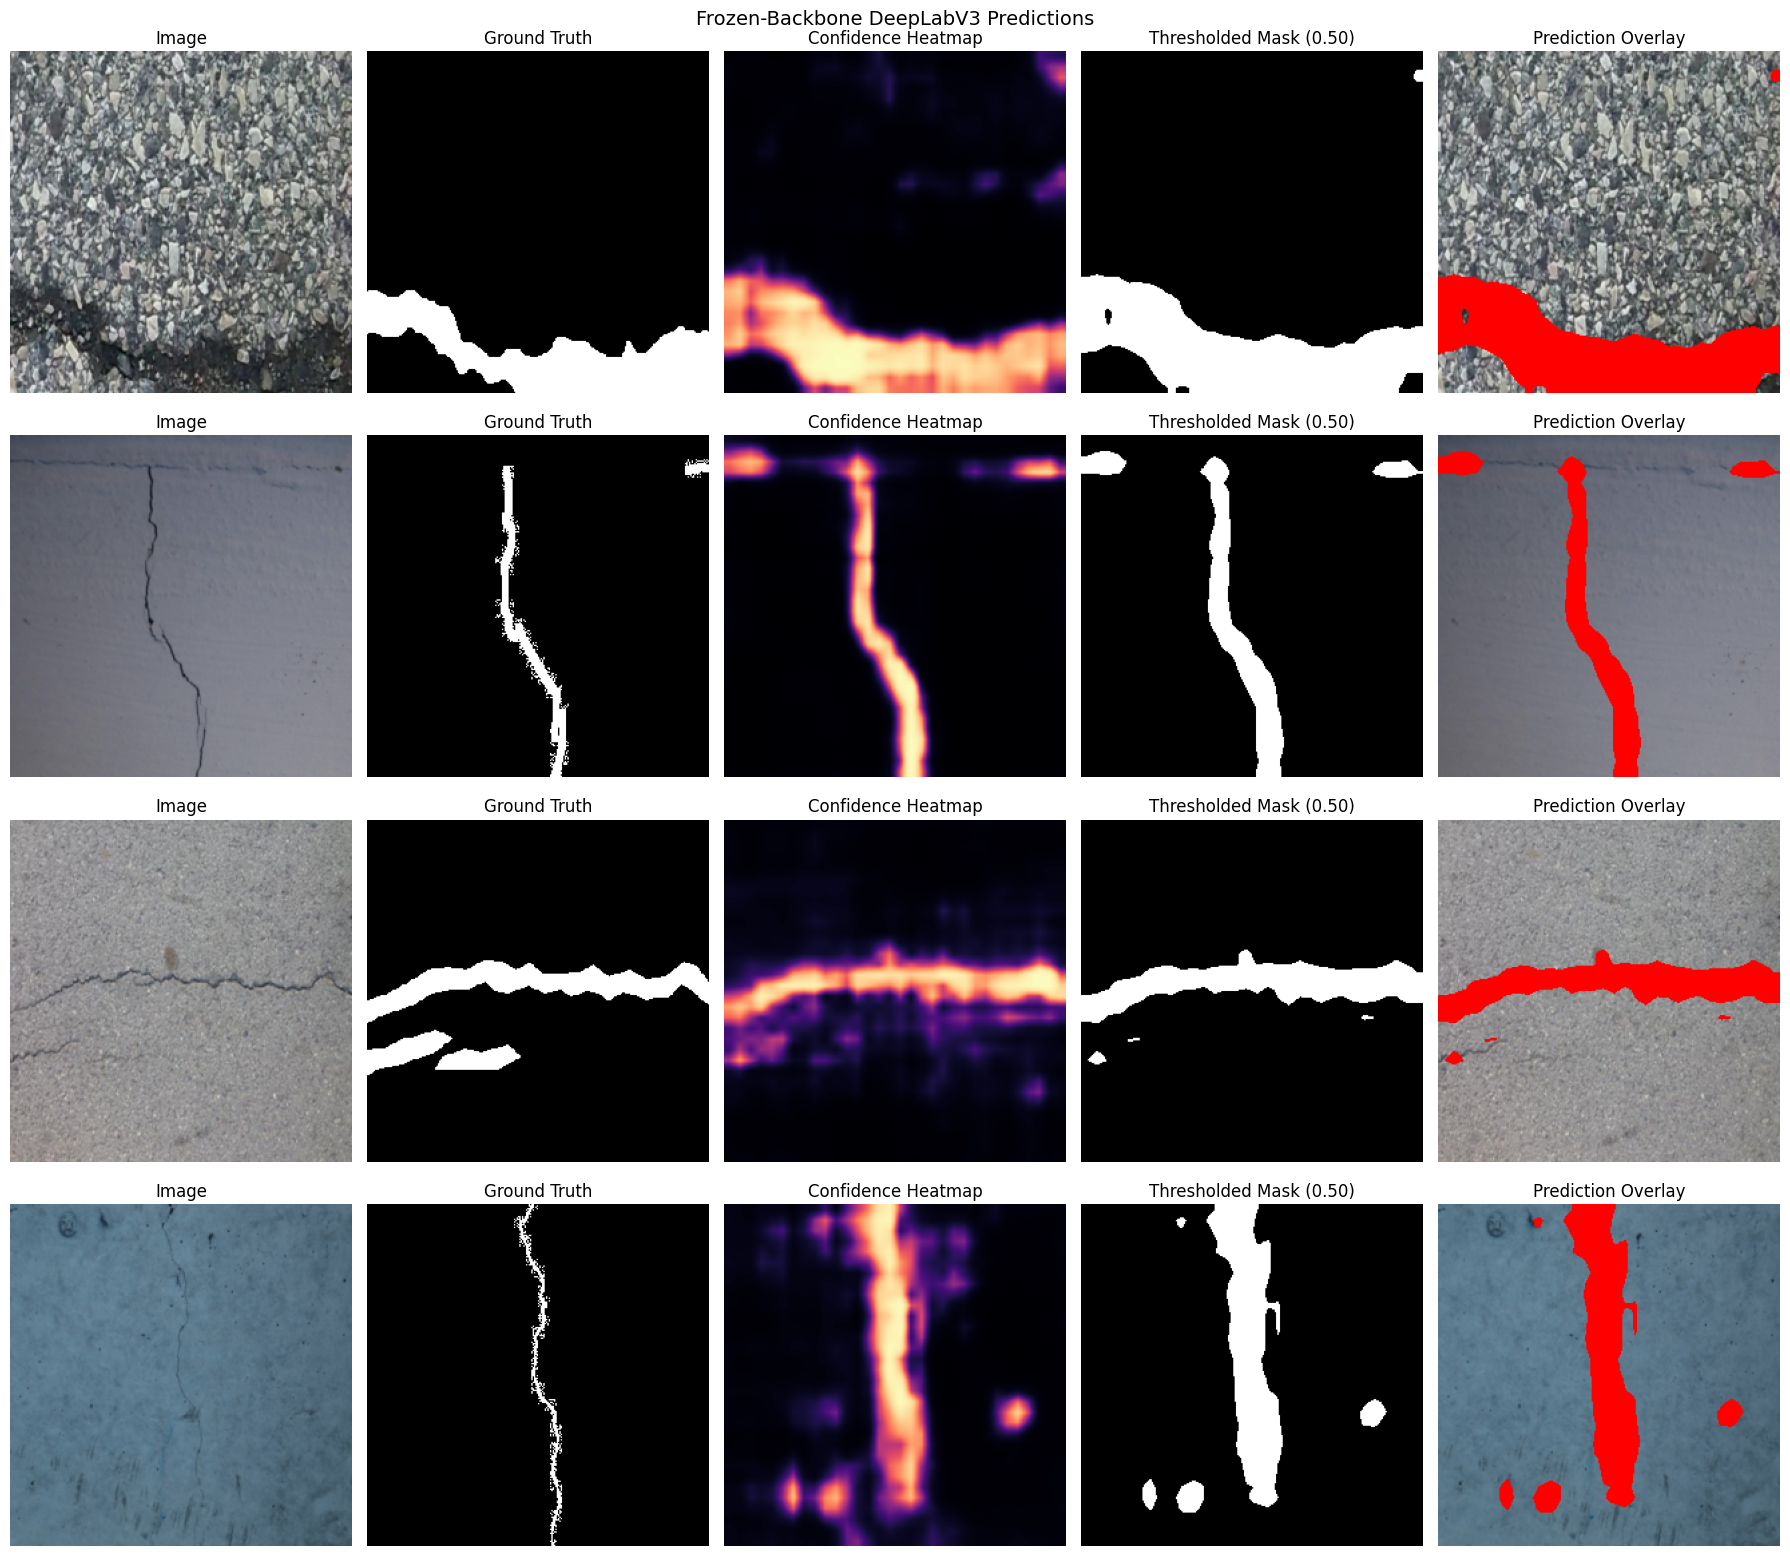

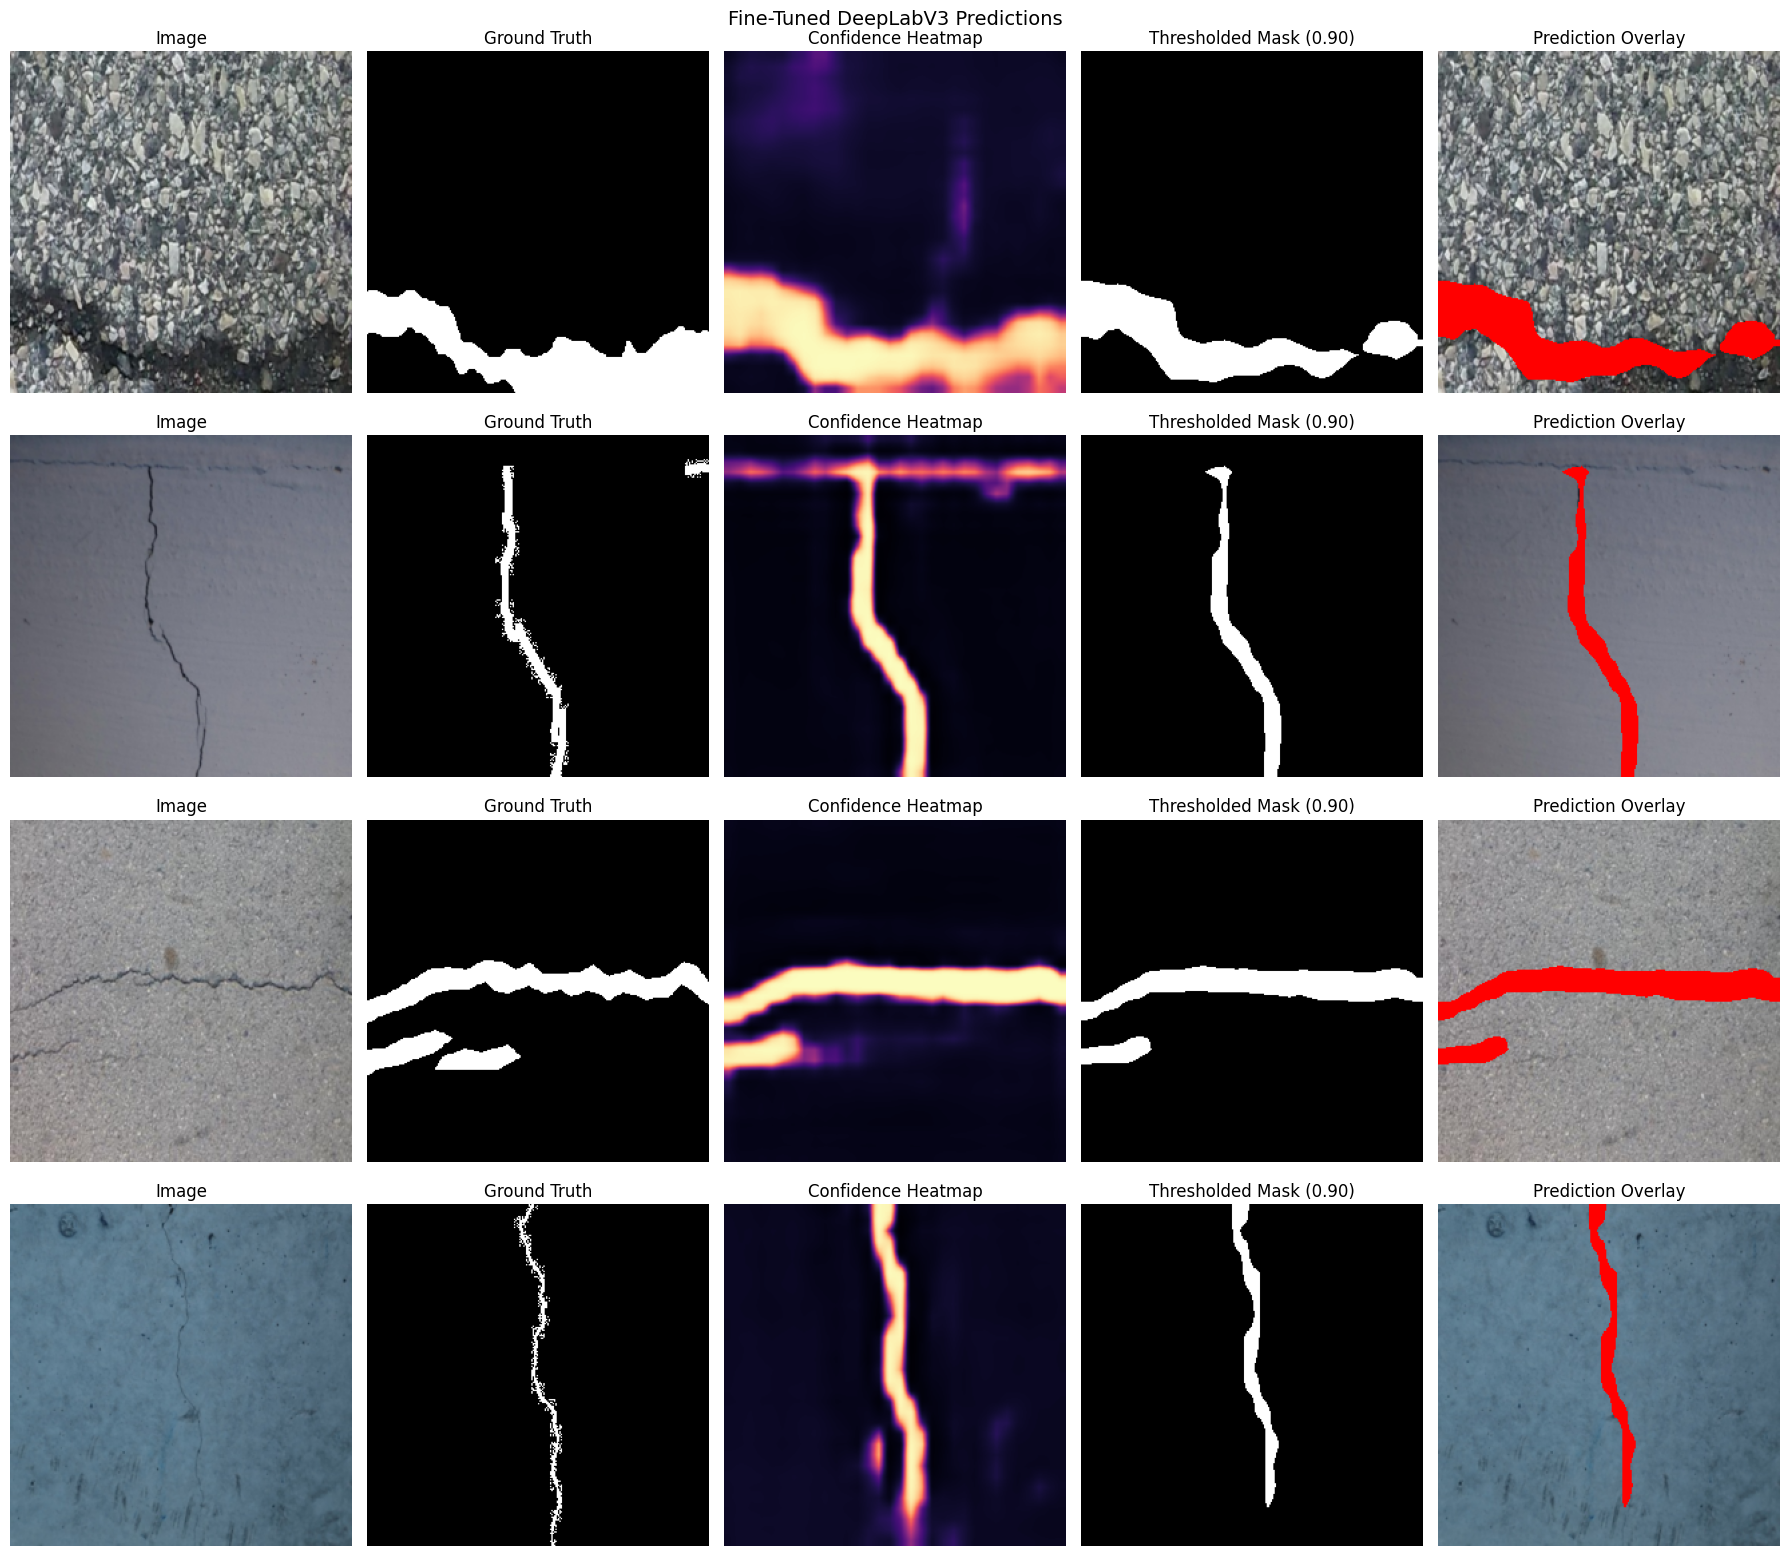

In [17]:
@torch.no_grad()
def prediction_grid(model, loader, threshold=0.5, max_samples=4, title="Prediction Grid"):
    """Visualize predictions from a binary segmentation model."""
    model.eval()
    model.to(DEVICE)

    images, masks, names = next(iter(loader))
    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    logits = forward_logits(model, images)
    probs = torch.sigmoid(logits)
    preds = probs > threshold

    n = min(max_samples, images.size(0))
    fig, axes = plt.subplots(n, 5, figsize=(18, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img_vis = denormalize_image(images[i].detach().cpu())
        gt_vis = masks[i, 0].detach().cpu().numpy()
        prob_vis = probs[i, 0].detach().cpu().numpy()
        pred_vis = preds[i, 0].detach().cpu().numpy()

        overlay = img_vis.copy()
        overlay[pred_vis.astype(bool)] = [1.0, 0.0, 0.0]

        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_vis, cmap="gray")
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(prob_vis, cmap="magma", vmin=0, vmax=1)
        axes[i, 2].set_title("Confidence Heatmap")
        axes[i, 2].axis("off")

        axes[i, 3].imshow(pred_vis, cmap="gray")
        axes[i, 3].set_title(f"Thresholded Mask ({threshold:.2f})")
        axes[i, 3].axis("off")

        axes[i, 4].imshow(overlay)
        axes[i, 4].set_title("Prediction Overlay")
        axes[i, 4].axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

prediction_grid(
    frozen_model,
    val_loader,
    threshold=DEFAULT_THRESHOLD,
    max_samples=4,
    title="Frozen-Backbone DeepLabV3 Predictions"
)

prediction_grid(
    finetuned_model,
    val_loader,
    threshold=best_threshold,
    max_samples=4,
    title="Fine-Tuned DeepLabV3 Predictions"
)

## 17. Pretrained versus Frozen versus Fine-Tuned Output Comparison

This section compares the three model states visually:

1. Original pretrained model before crack-specific learning.
2. Binary model trained with frozen backbone.
3. Binary model trained with full fine-tuning.

Loaded pretrained DeepLabV3-ResNet50 weights.


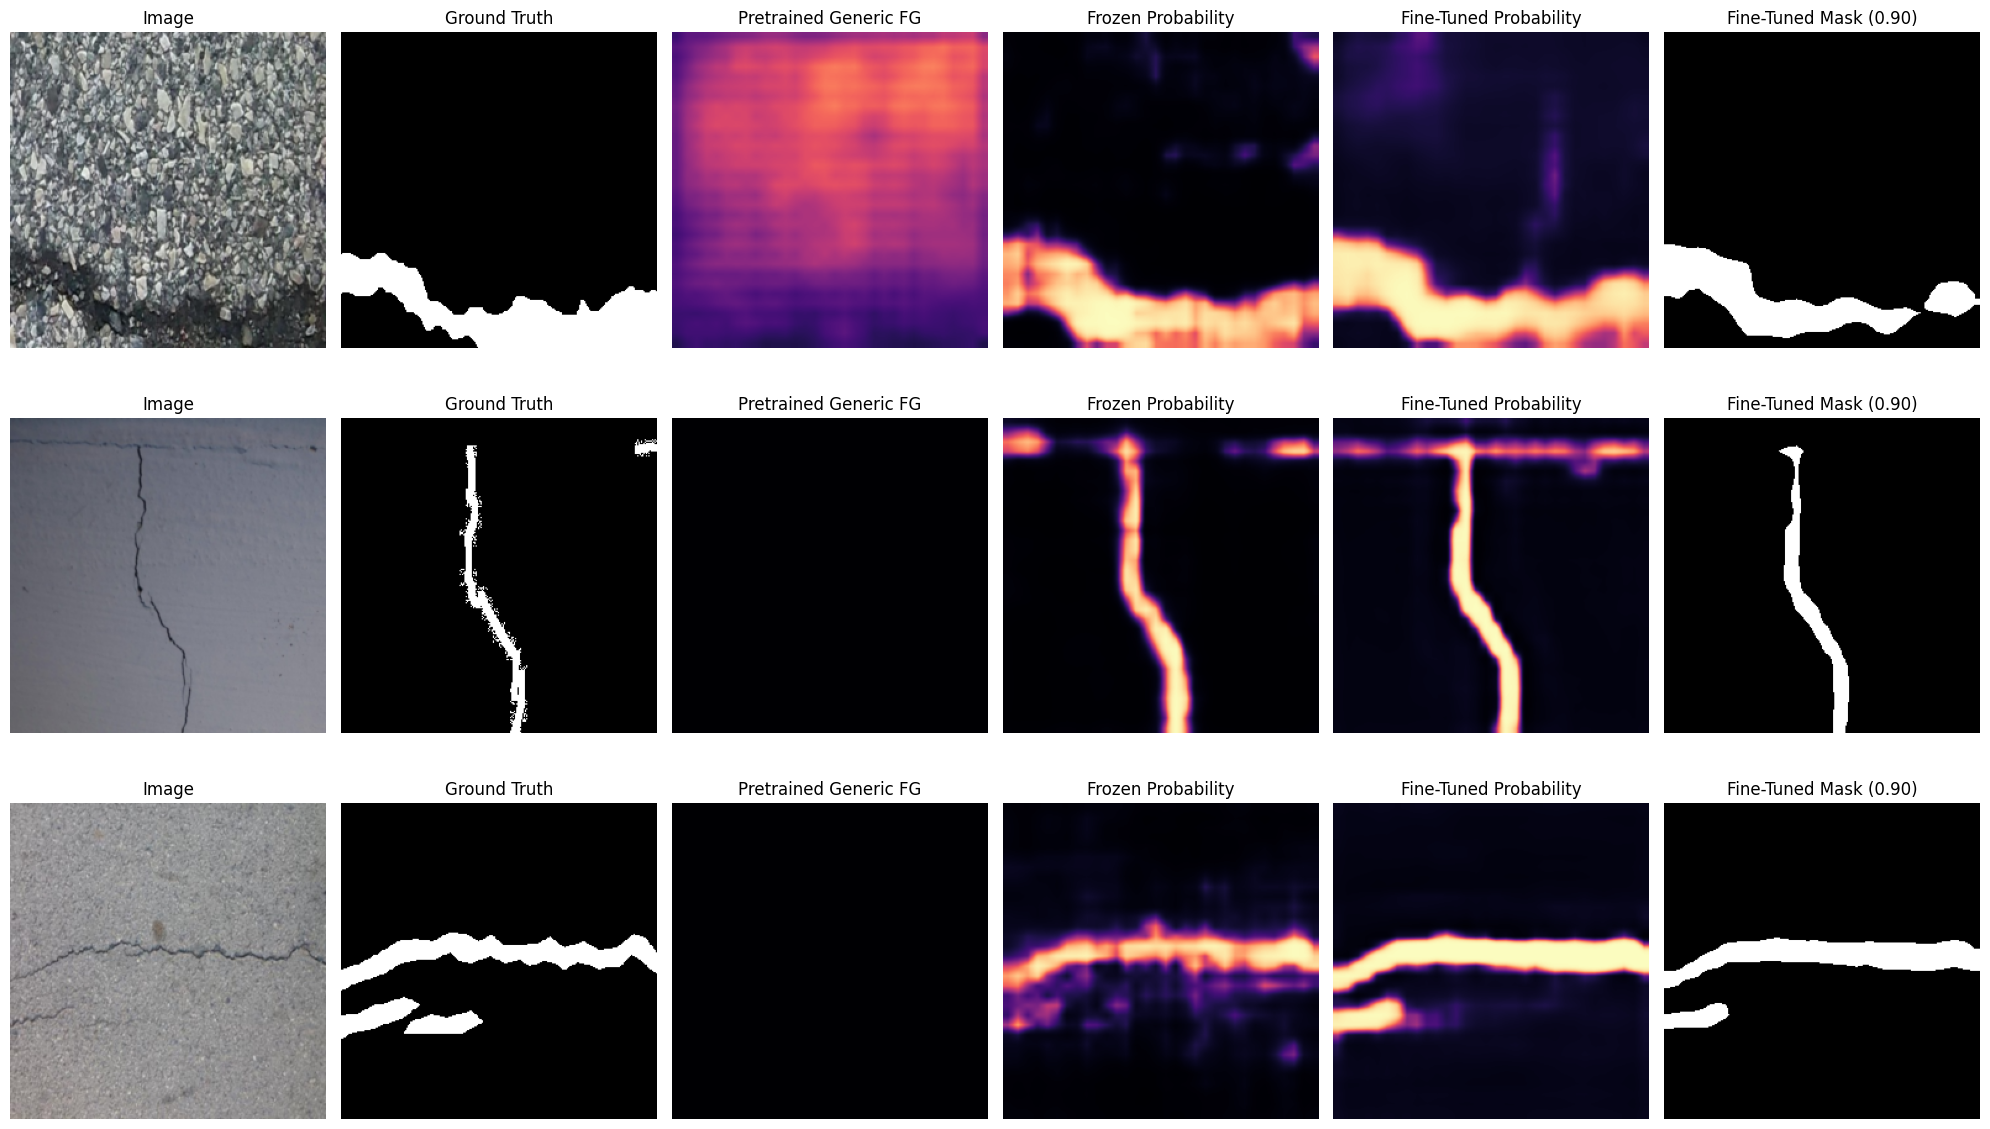

In [18]:
@torch.no_grad()
def compare_pretrained_frozen_finetuned(val_loader, frozen_model, finetuned_model, threshold=0.5, max_samples=3):
    """Compare starting pretrained behavior with two transfer-learning workflows."""
    pretrained_model, _ = build_pretrained_deeplab_multiclass()
    pretrained_model.to(DEVICE).eval()
    frozen_model.to(DEVICE).eval()
    finetuned_model.to(DEVICE).eval()

    images, masks, names = next(iter(val_loader))
    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    # Pretrained VOC foreground confidence.
    pretrained_logits = pretrained_model(images)["out"]
    pretrained_probs = torch.softmax(pretrained_logits, dim=1)
    pretrained_fg_conf = 1.0 - pretrained_probs[:, 0:1]

    # Crack-specific binary probabilities.
    frozen_probs = torch.sigmoid(forward_logits(frozen_model, images))
    finetuned_probs = torch.sigmoid(forward_logits(finetuned_model, images))

    n = min(max_samples, images.size(0))
    fig, axes = plt.subplots(n, 6, figsize=(20, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img_vis = denormalize_image(images[i].detach().cpu())
        gt_vis = masks[i, 0].detach().cpu().numpy()

        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_vis, cmap="gray")
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pretrained_fg_conf[i, 0].detach().cpu().numpy(), cmap="magma", vmin=0, vmax=1)
        axes[i, 2].set_title("Pretrained Generic FG")
        axes[i, 2].axis("off")

        axes[i, 3].imshow(frozen_probs[i, 0].detach().cpu().numpy(), cmap="magma", vmin=0, vmax=1)
        axes[i, 3].set_title("Frozen Probability")
        axes[i, 3].axis("off")

        axes[i, 4].imshow(finetuned_probs[i, 0].detach().cpu().numpy(), cmap="magma", vmin=0, vmax=1)
        axes[i, 4].set_title("Fine-Tuned Probability")
        axes[i, 4].axis("off")

        axes[i, 5].imshow((finetuned_probs[i, 0] > threshold).detach().cpu().numpy(), cmap="gray")
        axes[i, 5].set_title(f"Fine-Tuned Mask ({threshold:.2f})")
        axes[i, 5].axis("off")

    plt.tight_layout()
    plt.show()

    del pretrained_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

compare_pretrained_frozen_finetuned(
    val_loader=val_loader,
    frozen_model=frozen_model,
    finetuned_model=finetuned_model,
    threshold=best_threshold,
    max_samples=3,
)

## 18. Failure-Case Analysis

This section identifies validation images with low Dice score. These cases often include weak cracks, noisy textures, shadows, or noncrack surfaces that resemble crack patterns.

In [19]:
@torch.no_grad()
def collect_per_sample_metrics(model, loader, threshold=0.5):
    """Collect Dice and IoU for each validation image."""
    model.eval()
    model.to(DEVICE)

    rows = []
    saved_examples = []

    for images, masks, names in tqdm(loader, desc="Collecting per-sample metrics"):
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = forward_logits(model, images)
        probs = torch.sigmoid(logits)
        preds = probs > threshold

        for i in range(images.size(0)):
            tp, fp, fn, tn = compute_binary_stats(preds[i:i+1], masks[i:i+1] > 0.5)
            metrics = metrics_from_stats(tp, fp, fn, tn)

            rows.append({
                "Name": names[i],
                "IoU": metrics["IoU"],
                "Dice": metrics["Dice"],
                "Precision": metrics["Precision"],
                "Recall": metrics["Recall"],
            })

            saved_examples.append({
                "name": names[i],
                "image": images[i].detach().cpu(),
                "mask": masks[i, 0].detach().cpu(),
                "prob": probs[i, 0].detach().cpu(),
                "pred": preds[i, 0].detach().cpu(),
                "dice": metrics["Dice"],
                "iou": metrics["IoU"],
            })

    return pd.DataFrame(rows), saved_examples

per_sample_df, failure_examples = collect_per_sample_metrics(
    finetuned_model,
    val_loader,
    threshold=best_threshold,
)

per_sample_df = per_sample_df.sort_values("Dice", ascending=True)
per_sample_df.to_csv(OUTPUT_DIR / "per_sample_validation_metrics.csv", index=False)
per_sample_df.head(10)

,Name,IoU,Dice,Precision,Recall
6,noncrack_noncrack_concrete_wall_24_0.jpg.jpg,0.000000,0.000000,0.000000,0.000000
9,CRACK500_20160222_165012_641_361.jpg,0.000000,0.000000,0.000000,0.000000
10,noncrack_noncrack_concrete_wall_22_0.jpg.jpg,0.000000,0.000000,0.000000,0.000000
26,noncrack_noncrack_concrete_wall_13_0.jpg.jpg,0.000000,0.000000,0.000000,0.000000
36,noncrack_noncrack_concrete_wall_17_1.jpg.jpg,0.000000,0.000000,0.000000,0.000000
39,noncrack_noncrack_concrete_wall_10_1.jpg.jpg,0.000000,0.000000,0.000000,0.000000
38,cracktree200_6596.jpg,0.027962,0.054403,0.028173,0.788618
20,cracktree200_6358.jpg,0.065652,0.123214,0.073482,0.381215
37,CRACK500_20160222_114759_1281_721.jpg,0.158027,0.272924,0.557522,0.180688
25,CRACK500_20160308_073406_1281_721.jpg,0.171704,0.293085,0.761404,0.181468


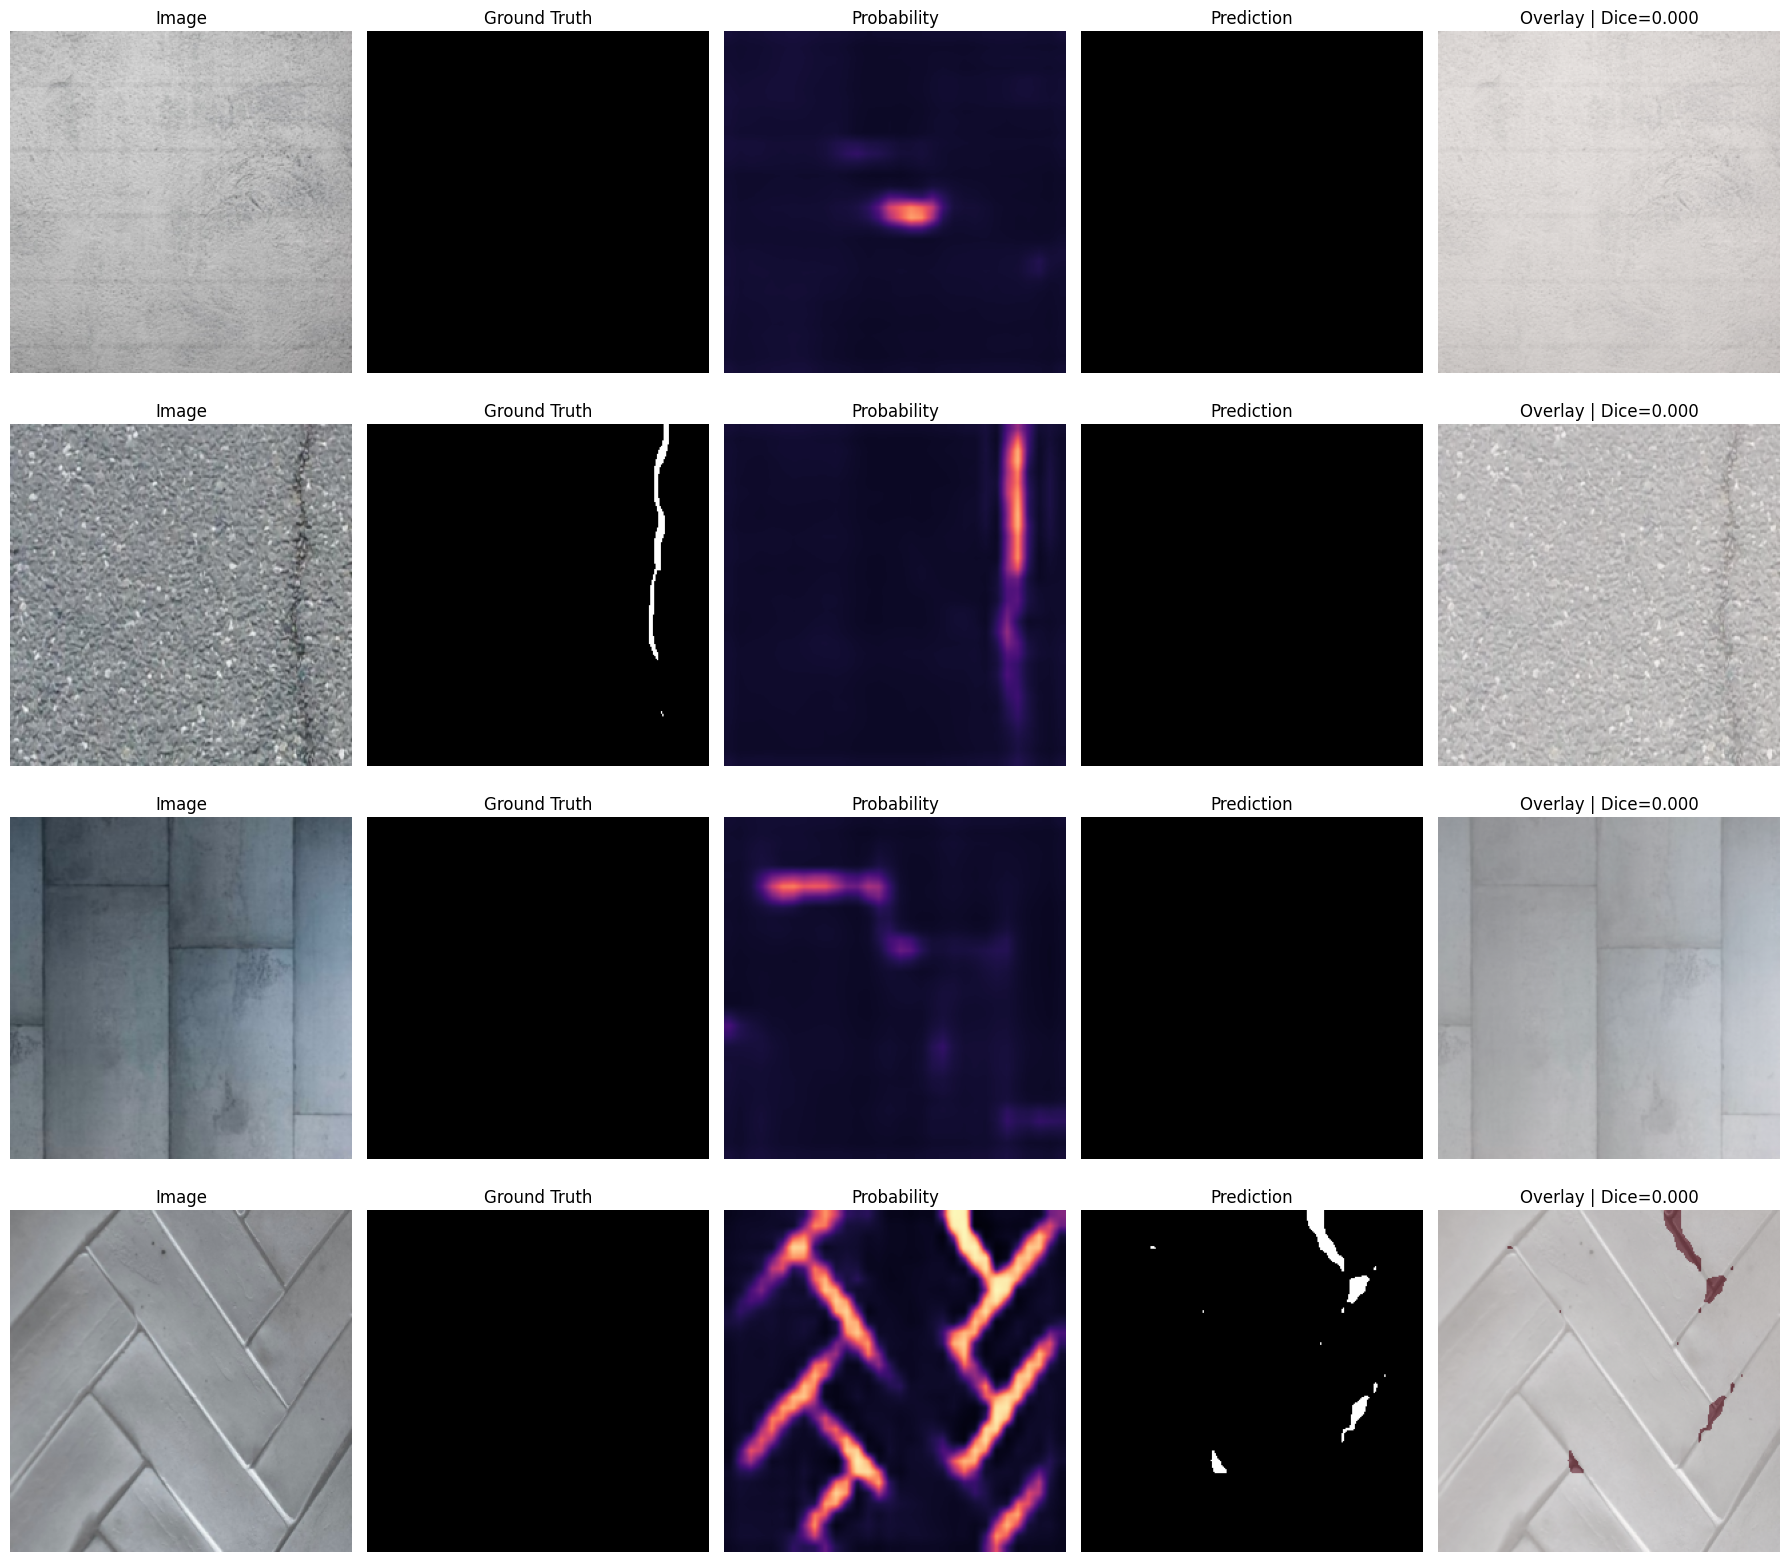

In [20]:
def show_failure_cases(examples, n=4):
    """Display lowest-Dice samples for diagnostic analysis."""
    examples = sorted(examples, key=lambda x: x["dice"])[:n]

    fig, axes = plt.subplots(len(examples), 5, figsize=(18, 4 * len(examples)))
    if len(examples) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, ex in enumerate(examples):
        img_vis = denormalize_image(ex["image"])
        gt_vis = ex["mask"].numpy()
        prob_vis = ex["prob"].numpy()
        pred_vis = ex["pred"].numpy()

        axes[row, 0].imshow(img_vis)
        axes[row, 0].set_title("Image")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(gt_vis, cmap="gray")
        axes[row, 1].set_title("Ground Truth")
        axes[row, 1].axis("off")

        axes[row, 2].imshow(prob_vis, cmap="magma", vmin=0, vmax=1)
        axes[row, 2].set_title("Probability")
        axes[row, 2].axis("off")

        axes[row, 3].imshow(pred_vis, cmap="gray")
        axes[row, 3].set_title("Prediction")
        axes[row, 3].axis("off")

        axes[row, 4].imshow(img_vis)
        axes[row, 4].imshow(pred_vis, cmap="Reds", alpha=0.45)
        axes[row, 4].set_title(f"Overlay | Dice={ex['dice']:.3f}")
        axes[row, 4].axis("off")

    plt.tight_layout()
    plt.show()

show_failure_cases(failure_examples, n=4)

### Failure-Case Discussion Template

Use the displayed low-Dice samples to write a short diagnostic note.

Common causes:

1. **Weak cracks**: very low contrast between crack and background.
2. **Noisy surfaces**: stains, shadows, texture, or rough surfaces may be mistaken for cracks.
3. **Thin structures**: one-pixel or narrow cracks are sensitive to resizing and thresholding.
4. **Noncrack images**: false positives may occur when surface texture resembles crack geometry.
5. **Annotation ambiguity**: small disagreements between prediction and mask can reduce Dice sharply for thin objects.

## 19. Save Predicted Masks in Batch

This section creates binary predicted masks for validation images and writes them to `/kaggle/working`. It is useful when students need output files for visual reports or downstream analysis.

In [21]:
@torch.no_grad()
def save_predicted_masks(model, dataset, output_dir, threshold=0.5, limit=None):
    """
    Save predicted binary masks one image at a time.

    Parameters:
    - model: trained binary segmentation model
    - dataset: CrackSegmentationDataset
    - output_dir: target folder
    - threshold: foreground threshold
    - limit: optional maximum number of saved masks
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    model.eval()
    model.to(DEVICE)

    indices = range(len(dataset)) if limit is None else range(min(limit, len(dataset)))

    for idx in tqdm(indices, desc="Saving predicted masks"):
        image, mask, name = dataset[idx]
        image_batch = image.unsqueeze(0).to(DEVICE)

        logits = forward_logits(model, image_batch)
        prob = torch.sigmoid(logits)[0, 0].detach().cpu().numpy()
        pred = (prob > threshold).astype(np.uint8) * 255

        out_name = Path(name).stem + "_pred_mask.png"
        Image.fromarray(pred).save(output_dir / out_name)

    print("Saved masks to:", output_dir)

PRED_MASK_DIR = OUTPUT_DIR / "predicted_masks_finetuned"
save_predicted_masks(
    model=finetuned_model,
    dataset=val_ds,
    output_dir=PRED_MASK_DIR,
    threshold=best_threshold,
    limit=None,
)

Saving predicted masks:   0%|          | 0/40 [00:00<?, ?it/s]

Saved masks to: /kaggle/working/seg04_transfer_learning_outputs/predicted_masks_finetuned


## 20. Save Model Checkpoints

The following cell saves the frozen-backbone and fine-tuned DeepLabV3 weights. These checkpoints can be loaded later for inference or further training.

In [22]:
torch.save(
    frozen_model.state_dict(),
    OUTPUT_DIR / "deeplabv3_frozen_backbone_binary_crack.pth"
)

torch.save(
    finetuned_model.state_dict(),
    OUTPUT_DIR / "deeplabv3_finetuned_binary_crack.pth"
)

print("Saved checkpoints:")
print(OUTPUT_DIR / "deeplabv3_frozen_backbone_binary_crack.pth")
print(OUTPUT_DIR / "deeplabv3_finetuned_binary_crack.pth")

Saved checkpoints:
/kaggle/working/seg04_transfer_learning_outputs/deeplabv3_frozen_backbone_binary_crack.pth
/kaggle/working/seg04_transfer_learning_outputs/deeplabv3_finetuned_binary_crack.pth


## 21. Summary

This notebook demonstrated a transfer-learning workflow for binary crack segmentation using pretrained `torchvision` semantic segmentation models.

### What was covered

1. Dataset discovery and image-mask pairing from the Kaggle crack segmentation dataset.
2. Pretrained DeepLabV3 inference before task-specific fine-tuning.
3. Binary classifier-head replacement for crack foreground prediction.
4. Frozen-backbone training and full fine-tuning.
5. BCE + Dice loss for foreground/background imbalance.
6. Mixed precision training for faster GPU execution.
7. Validation metric comparison using IoU, Dice, precision, and recall.
8. Confidence heatmaps, threshold sensitivity analysis, and failure-case review.

### How to improve the experiment

For stronger results, increase image size, train on the full dataset, use longer schedules, tune thresholds on a held-out set, test DeepLabV3 versus FCN, and compare with U-Net or transformer-based segmentation models under the same split.